# Business Analytics Capstone #8: Short-Term Electricity Demand Forecasting & Peak Capacity Planning

**Course:** Master of Data Science — Business Analytics (HUST)  
**Dataset:** UCI Power Consumption of Tetouan City (`DOI: 10.24432/C5B034`, 2017 10-minute telemetry aggregated to hourly load)  
**Frameworks Applied:** CRISP-DM & DOC Problem Framing (`BA01`), 6-Dimension Data Quality Scorecard & Leakage-Safe Feature Engineering (`BA3`), Hypothesis-Driven EDA & Simpson's Paradox Audit (`BA4`), Regularized Regression, Quantile Forecasting & TreeSHAP Explainability (`BA6`).

---

## 1. Business Framing (DOC Framework) & Setup
- **Decision (D):** How much short-term standby capacity/reserve should grid operators commit ahead of each operating hour—especially during evening peak windows (`17:00–21:00`)—to prevent capacity threshold breaches without over-committing costly spinning reserves?
- **Unit of Analysis:** 1 complete operating hour $T$.
- **Target ($y_T$):** `system_load` = `Zone 1 + Zone 2 + Zone 3` hourly mean demand.
- **Horizons:** Primary `1h` ahead, plus `6h` (intra-day) and `24h` (day-ahead) stretch horizons.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..').resolve() if Path('..', 'src').exists() else Path('.').resolve()
sys.path.insert(0, str(ROOT / 'src'))

from config import (
    PROCESSED_DATA, DQ_SCORECARD_JSON, PREDICTIONS, METRICS,
    BACKTEST_METRICS, SENSITIVITY_CSV, HORIZON_METRICS, ZONE_METRICS,
    SHAP_SUMMARY_CSV, SHAP_LOCAL_JSON, ZONE_COLS, WEATHER_COLS, TARGET
)

plt.rcParams['figure.figsize'] = (11, 4.2)
plt.rcParams['axes.grid'] = True
print('Repository root:', ROOT)

Repository root: /Users/johnvu/Documents/SOICT/Bussiness Analysis/business-analyst-hust


## 2. Six-Dimension Data Quality Scorecard & Outlier vs. True Peak Audit (`BA3`)
Before modeling, we verify the 6 dimensions of data quality (**Completeness, Uniqueness/Consistency, Timeliness/Continuity, Validity, Accuracy/Outliers, and Provenance**) and test whether upper-tail values represent sensor glitches or genuine physical peak demand.

In [2]:
dq = json.loads(DQ_SCORECARD_JSON.read_text(encoding='utf-8'))
dq_table = pd.DataFrame([
    {'Dimension': k.replace('_', ' ').title(), **v}
    for k, v in dq['dimensions'].items()
])
display(dq_table)
print('\nOutlier vs. Peak Audit Summary:')
print(json.dumps(dq['outlier_summary'], indent=2))

Dimension,metric,value,sla_threshold,status
Completeness,Missing cell rate (%),0.0,< 2.0%,PASS
Uniqueness Consistency,Duplicate timestamp rate (%),0.0,< 0.5%,PASS
Timeliness Continuity,Non-10-minute interval gaps,0,0 gaps,PASS
Validity,Out-of-range physical readings,0,< 0.1%,PASS
Accuracy Outlier Treatment,Hourly load > Q3 + 1.5*IQR / |Z| > 3,19 IQR high / 35 |Z|>3,Retain genuine summer peak signal (no blind winsorization),PASS
Provenance,Source DOI & CC BY 4.0 license verified,10.24432/C5B034,Documented URL & download log,PASS



Outlier vs. Peak Audit Summary:
{
  "system_load_q25": 56585.36248458333,
  "system_load_q75": 83781.62649958333,
  "system_load_iqr_upper": 124576.02252208334,
  "system_load_iqr_lower": 15790.966462083328,
  "hours_above_iqr_upper": 19,
  "hours_abs_z_gt_3": 35,
  "decision": "Upper-tail observations correspond to July-August evening cooling peaks; retained as critical target signal for capacity planning."
}


## 3. Hypothesis-Driven Exploratory Data Analysis (`BA4`)
We test three structured business hypotheses:
1. **H1 (Diurnal & Weekly Regime):** System load exhibits a strong evening ramp (`17:00–21:00`) and lower weekend demand.
2. **H2 (Nonlinear Thermal Response & Simpson's Paradox):** Pooling all hours masks or reverses the temperature–load relationship (Simpson's Paradox) because daytime solar heating coincides with lower lighting load in winter, whereas stratifying by **Summer Evening Peak (`Jul–Aug, 18:00–21:00`)** vs. **Winter Midday** reveals a strong positive cooling demand slope above `22°C`.
3. **H3 (Zonal Heterogeneity):** Zone 3 has much stronger summer peaking variability than Zone 1 and Zone 2.

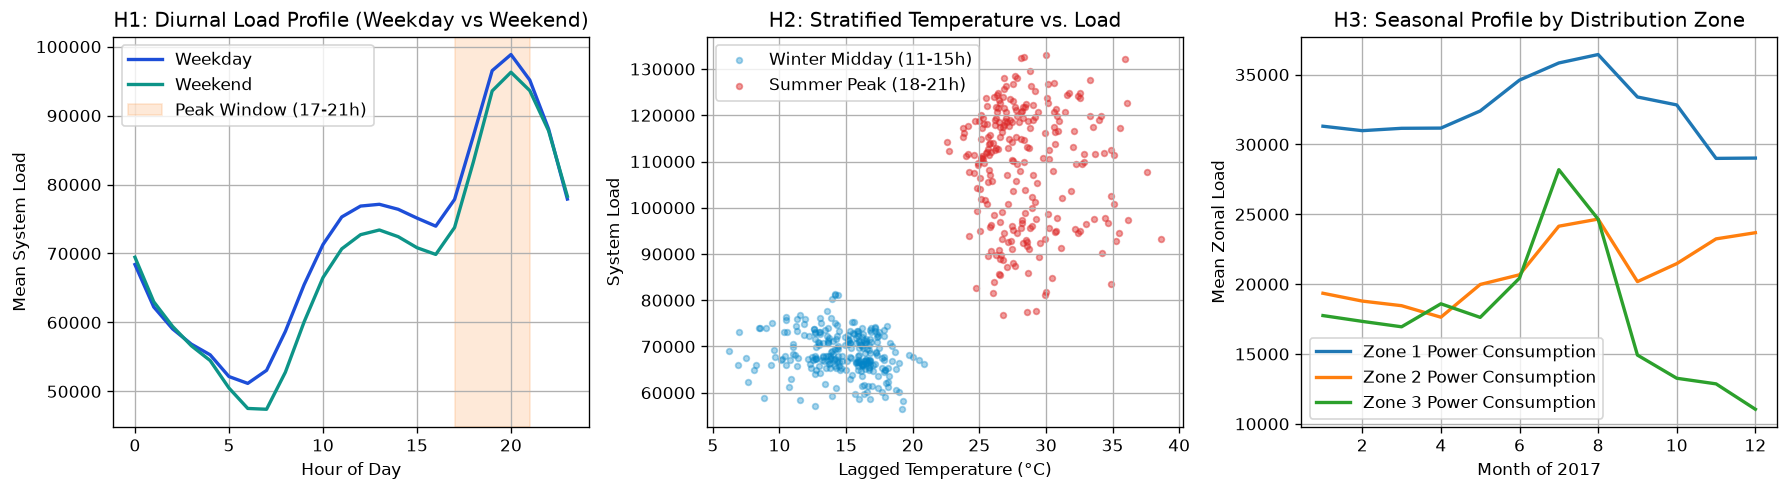

Pooled Temp-Load Corr: 0.524 | Summer Evening Peak Corr: -0.042 | Winter Midday Corr: -0.190


In [3]:
df = pd.read_csv(PROCESSED_DATA, parse_dates=['timestamp'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# H1: Diurnal profile Weekday vs Weekend
diurnal = df.groupby(['hour', 'is_weekend'])[TARGET].mean().unstack()
diurnal.columns = ['Weekday', 'Weekend']
diurnal.plot(ax=axes[0], lw=2, color=['#1d4ed8', '#0d9488'])
axes[0].axvspan(17, 21, color='#fb923c', alpha=0.2, label='Peak Window (17-21h)')
axes[0].set_title('H1: Diurnal Load Profile (Weekday vs Weekend)')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Mean System Load')
axes[0].legend()

# H2: Simpson's Paradox / Stratified Temperature vs Load
summer_peak = df[(df['month'].isin([7, 8])) & (df['hour'].between(18, 21))]
winter_midday = df[(df['month'].isin([1, 12])) & (df['hour'].between(11, 15))]
axes[1].scatter(winter_midday['temperature_lag_1h'], winter_midday[TARGET], alpha=0.35, s=12, label='Winter Midday (11-15h)', color='#0284c7')
axes[1].scatter(summer_peak['temperature_lag_1h'], summer_peak[TARGET], alpha=0.45, s=12, label='Summer Peak (18-21h)', color='#dc2626')
axes[1].set_title('H2: Stratified Temperature vs. Load')
axes[1].set_xlabel('Lagged Temperature (°C)')
axes[1].set_ylabel('System Load')
axes[1].legend()

# H3: Monthly Zone Profiles
monthly_zones = df.groupby('month')[ZONE_COLS].mean()
monthly_zones.plot(ax=axes[2], lw=2)
axes[2].set_title('H3: Seasonal Profile by Distribution Zone')
axes[2].set_xlabel('Month of 2017')
axes[2].set_ylabel('Mean Zonal Load')
plt.tight_layout()
plt.show()

pooled_corr = df['temperature_lag_1h'].corr(df[TARGET])
summer_peak_corr = summer_peak['temperature_lag_1h'].corr(summer_peak[TARGET])
winter_mid_corr = winter_midday['temperature_lag_1h'].corr(winter_midday[TARGET])
print(f'Pooled Temp-Load Corr: {pooled_corr:.3f} | Summer Evening Peak Corr: {summer_peak_corr:.3f} | Winter Midday Corr: {winter_mid_corr:.3f}')

## 4. Point & Probabilistic (`P10`/`P50`/`P90`) Forecasting & 5-Fold Rolling Backtesting
We compare:
- **Weekly Seasonal Naive (`168h`)** and **Daily Naive (`24h`)**
- **Standardized Ridge Regression** (`StandardScaler` + `RidgeCV` with `TimeSeriesSplit`)
- **LightGBM Point (`L1` loss)**
- **Conformalized Quantile LightGBM (`P10`, `P50`, `P90`)** calibrated on the November 2017 validation split.

In [4]:
metrics = json.loads(METRICS.read_text(encoding='utf-8'))
preds = pd.read_csv(PREDICTIONS, parse_dates=['timestamp'])
bt = json.loads(BACKTEST_METRICS.read_text(encoding='utf-8'))

holdout_summary = pd.DataFrame([
    {'Model': 'Seasonal Naive (168h)', **metrics['seasonal_naive'], 'mase_vs_seasonal_naive': 1.0},
    {'Model': 'Seasonal Naive (24h)', **metrics['seasonal_naive_24h']},
    {'Model': 'Standardized Ridge Regression', **metrics['ridge_regression']},
    {'Model': 'LightGBM Point (L1)', **metrics['lightgbm']},
])
holdout_summary['WAPE (%)'] = (holdout_summary['wape'] * 100).round(2)
display(holdout_summary[['Model', 'mae', 'rmse', 'WAPE (%)', 'mase_vs_seasonal_naive']])

print('\nProbabilistic Interval Calibration (December 2017 Test Set):')
prob_df = pd.DataFrame([
    {'Interval Method': 'Raw LightGBM Quantile (P10-P90)', **metrics['lightgbm_probabilistic_raw']},
    {'Interval Method': 'Validation-Calibrated CQR (P10-P90)', **{k: v for k, v in metrics['lightgbm_probabilistic_calibrated'].items() if k != 'validation_cqr_padding'}},
])
display(prob_df[['Interval Method', 'nominal_coverage', 'empirical_coverage', 'mean_pinball_loss', 'mean_interval_width', 'winkler_score']])

print('\n5-Fold Expanding-Window Rolling Backtest (Aug–Dec 2017):')
bt_df = pd.DataFrame(bt['folds'])
display(bt_df[['fold', 'test_start', 'test_end', 'lightgbm_wape', 'ridge_wape', 'seasonal_naive_wape', 'lightgbm_mase', 'empirical_coverage_80', 'peak_recall_p80', 'mean_abs_peak_timing_error_hours']])

Model,mae,rmse,WAPE (%),mase_vs_seasonal_naive
Seasonal Naive (168h),1775.389183,2619.849090,2.78,1.000000
Seasonal Naive (24h),2071.536492,3296.291702,3.25,1.166807
Standardized Ridge Regression,674.844294,974.517286,1.06,0.380111
LightGBM Point (L1),903.829193,1250.346343,1.42,0.509088


Interval Method,nominal_coverage,empirical_coverage,mean_pinball_loss,mean_interval_width,winkler_score
Raw LightGBM Quantile (P10-P90),0.8,0.769444,298.410022,2775.602920,4433.154682
Validation-Calibrated CQR (P10-P90),0.8,0.877778,301.017828,3477.817618,4511.388881


fold,test_start,test_end,lightgbm_wape,ridge_wape,seasonal_naive_wape,lightgbm_mase,empirical_coverage_80,peak_recall_p80,mean_abs_peak_timing_error_hours
1,2017-08-03 00:00:00,2017-09-01 23:00:00,0.022045,0.019103,0.059630,0.369692,0.809722,0.990066,0.166667
2,2017-09-02 00:00:00,2017-10-01 23:00:00,0.018825,0.021699,0.060576,0.310771,0.898611,0.962963,0.233333
3,2017-10-02 00:00:00,2017-10-31 23:00:00,0.011908,0.012481,0.020927,0.569003,0.788889,0.888889,0.233333
4,2017-11-01 00:00:00,2017-11-30 23:00:00,0.015999,0.013621,0.037259,0.429404,0.720833,0.933333,0.133333
5,2017-12-01 00:00:00,2017-12-30 23:00:00,0.012120,0.010586,0.027849,0.435203,0.852778,0.848485,0.300000



Probabilistic Interval Calibration (December 2017 Test Set):

5-Fold Expanding-Window Rolling Backtest (Aug–Dec 2017):


### Visualizing Actual vs. Forecast Load & Calibrated `P10–P90` Intervals During Peak Week (`Dec 23–30, 2017`)

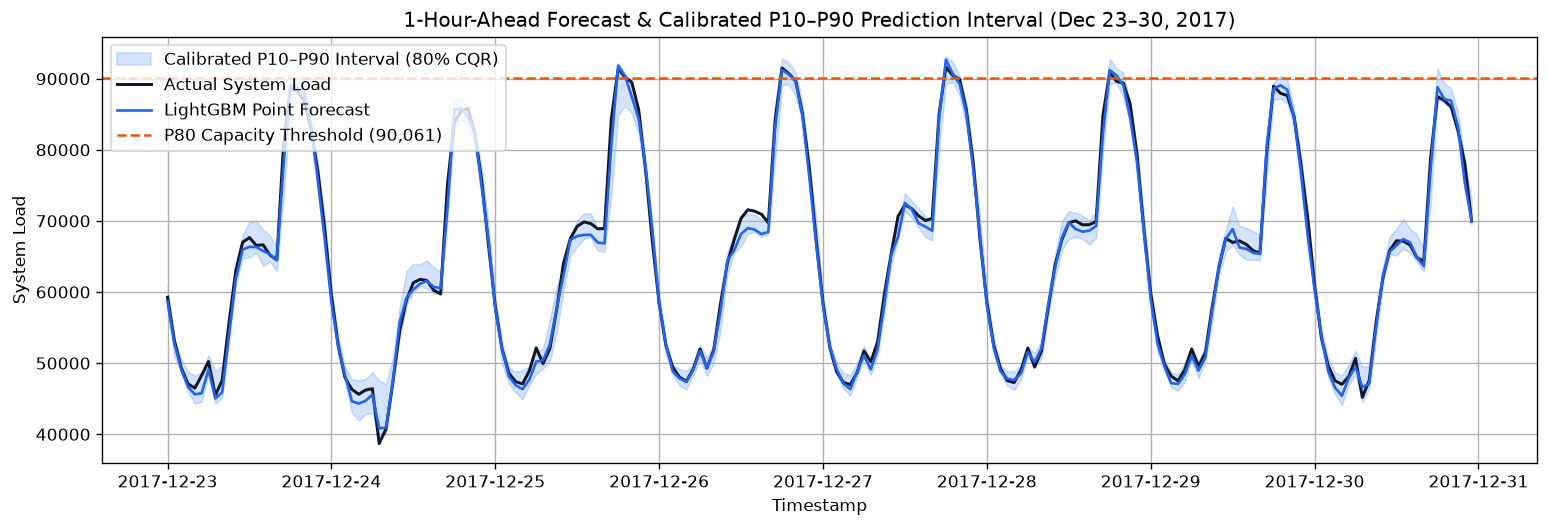

In [5]:
peak_week = preds[preds['timestamp'] >= '2017-12-23'].copy()
plt.figure(figsize=(13, 4.5))
plt.fill_between(
    peak_week['timestamp'],
    peak_week['prediction_lgbm_p10'],
    peak_week['prediction_lgbm_p90'],
    color='#3b82f6', alpha=0.22, label='Calibrated P10–P90 Interval (80% CQR)'
)
plt.plot(peak_week['timestamp'], peak_week['system_load'], color='#0f172a', lw=1.8, label='Actual System Load')
plt.plot(peak_week['timestamp'], peak_week['prediction_lgbm'], color='#2563eb', lw=1.6, label='LightGBM Point Forecast')
plt.axhline(peak_week['capacity_threshold'].iloc[0], color='#ea580c', ls='--', lw=1.5, label='P80 Capacity Threshold (90,061)')
plt.title('1-Hour-Ahead Forecast & Calibrated P10–P90 Prediction Interval (Dec 23–30, 2017)')
plt.xlabel('Timestamp')
plt.ylabel('System Load')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 5. Multi-Horizon (`1h`, `6h`, `24h`) & Zone-Specific vs. Pooled Comparison (Stretch Goals)

In [6]:
hz = json.loads(HORIZON_METRICS.read_text(encoding='utf-8'))
zn = json.loads(ZONE_METRICS.read_text(encoding='utf-8'))

hz_table = pd.DataFrame([
    {
        'Horizon': k,
        'Min Lag (h)': v['min_feature_lag_hours'],
        'LightGBM WAPE (%)': round(v['lightgbm']['wape'] * 100, 2),
        'Ridge WAPE (%)': round(v['ridge']['wape'] * 100, 2),
        'MASE vs 168h': round(v['lightgbm']['mase_vs_seasonal_naive'], 3),
        'P10-P90 Coverage (%)': round(v['probabilistic']['empirical_coverage'] * 100, 1),
        'Mean Pinball Loss': round(v['probabilistic']['mean_pinball_loss'], 1),
        'Peak Recall P80 (%)': round(v['peak_metrics']['peak_recall'] * 100, 1),
        'Peak Timing Error (h)': round(v['peak_metrics']['mean_abs_peak_timing_error_hours'], 2),
    }
    for k, v in hz.items()
])
print('Multi-Horizon Forecasting Performance (1h, 6h, 24h Ahead):')
display(hz_table)

zn_table = pd.DataFrame([
    {
        'Model / Zone Subgroup': 'System Load (Direct Combined Model)',
        'Load Share (%)': 100.0,
        'LightGBM WAPE (%)': round(zn['direct_combined_model']['wape'] * 100, 2),
        'MASE': round(zn['direct_combined_model']['mase_vs_seasonal_naive'], 3),
        'Peak Recall P80 (%)': round(zn['direct_combined_model']['peak_metrics_p80']['peak_recall'] * 100, 1),
        'Peak Timing Error (h)': round(zn['direct_combined_model']['peak_metrics_p80']['mean_abs_peak_timing_error_hours'], 2),
    },
    {
        'Model / Zone Subgroup': 'System Load (Bottom-Up Sum of Zone Models)',
        'Load Share (%)': 100.0,
        'LightGBM WAPE (%)': round(zn['bottom_up_zone_sum_model']['wape'] * 100, 2),
        'MASE': round(zn['bottom_up_zone_sum_model']['mase_vs_seasonal_naive'], 3),
        'Peak Recall P80 (%)': round(zn['bottom_up_zone_sum_model']['peak_metrics_p80']['peak_recall'] * 100, 1),
        'Peak Timing Error (h)': round(zn['bottom_up_zone_sum_model']['peak_metrics_p80']['mean_abs_peak_timing_error_hours'], 2),
    },
] + [
    {
        'Model / Zone Subgroup': z_name,
        'Load Share (%)': round(z_val['share_of_system_load_pct'], 1),
        'LightGBM WAPE (%)': round(z_val['lightgbm']['wape'] * 100, 2),
        'MASE': round(z_val['lightgbm']['mase_vs_seasonal_naive'], 3),
        'Peak Recall P80 (%)': round(z_val['peak_metrics_p80']['peak_recall'] * 100, 1) if z_val['peak_metrics_p80']['peak_recall'] is not None else None,
        'Peak Timing Error (h)': round(z_val['peak_metrics_p80']['mean_abs_peak_timing_error_hours'], 2),
    }
    for z_name, z_val in zn['zones'].items()
])
print('\nDirect Combined vs. Bottom-Up Zone Sum & Subgroup Fairness Audit:')
display(zn_table)

Horizon,Min Lag (h),LightGBM WAPE (%),Ridge WAPE (%),MASE vs 168h,P10-P90 Coverage (%),Mean Pinball Loss,Peak Recall P80 (%),Peak Timing Error (h)
1h_ahead,1,1.42,1.06,0.511,88.3,299.0,80.0,0.23
6h_ahead,6,2.11,2.42,0.757,89.2,494.5,60.0,0.43
24h_ahead,24,2.30,2.60,0.828,85.7,515.9,73.3,0.37


Model / Zone Subgroup,Load Share (%),LightGBM WAPE (%),MASE,Peak Recall P80 (%),Peak Timing Error (h)
System Load (Direct Combined Model),100.0,1.42,0.511,80.0,0.23
System Load (Bottom-Up Sum of Zone Models),100.0,1.49,0.534,53.3,0.37
Zone 1 Power Consumption,45.5,1.76,0.655,92.9,0.13
Zone 2 Power Consumption,37.1,2.08,0.551,99.0,0.53
Zone 3 Power Consumption,17.3,3.48,0.685,NaN,0.77


Multi-Horizon Forecasting Performance (1h, 6h, 24h Ahead):

Direct Combined vs. Bottom-Up Zone Sum & Subgroup Fairness Audit:


## 6. Regression Diagnostics & Explainability (TreeSHAP & Permutation Importance, `BA6`)

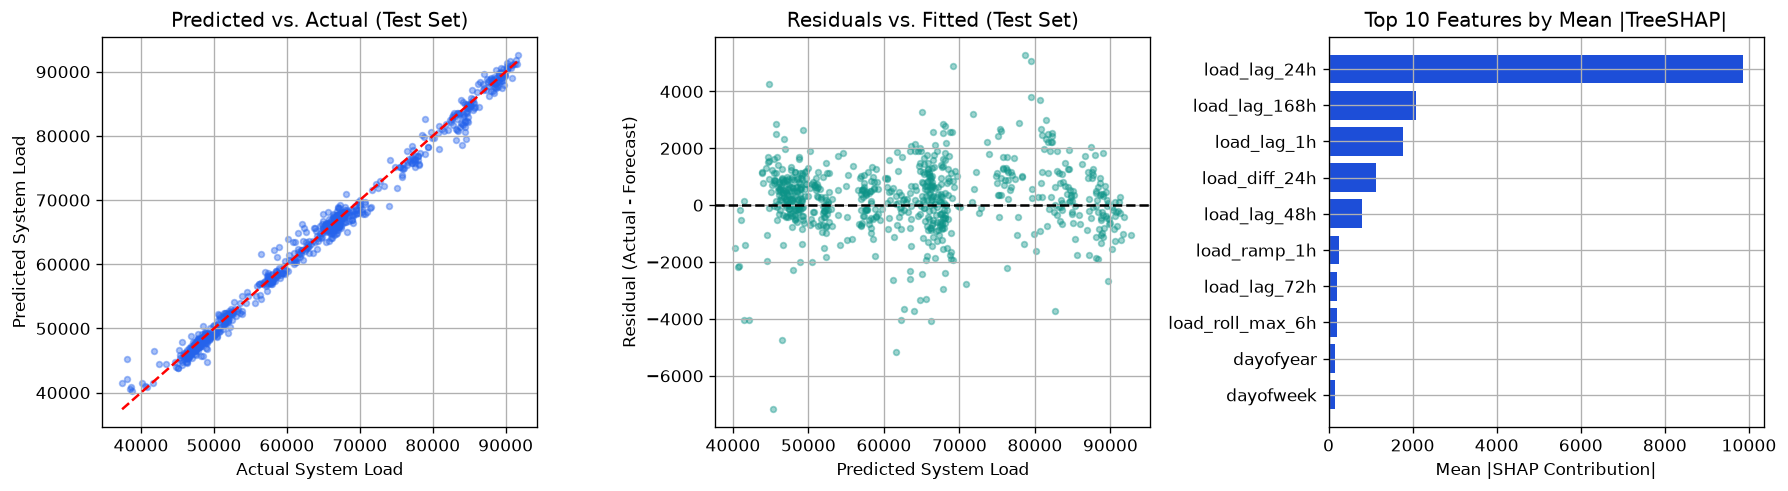

feature,mean_abs_shap,permutation_mae_increase,permutation_mae_std,lgbm_gain
load_lag_24h,9853.151336,9085.165259,329.147028,261343.181131
load_lag_168h,2070.554878,1727.297365,72.529140,51281.527529
load_lag_1h,1779.429636,1228.849350,79.754991,46365.610484
load_diff_24h,1137.259046,1123.932116,19.916980,61507.721080
load_lag_48h,799.004747,739.316962,24.847348,21241.410810
load_ramp_1h,245.867433,179.700760,16.665918,10793.636133
load_lag_72h,199.215443,80.402355,10.600211,7055.910276
load_roll_max_6h,192.382023,69.417521,15.943908,3874.363724
dayofyear,153.791262,0.000000,0.000000,2772.740999
dayofweek,146.236782,46.682829,6.068868,6225.995243


feature,feature_value,shap_contribution
load_lag_24h,91489.939032,13784.153487
load_lag_168h,90833.952585,1779.744129
load_lag_1h,84985.227678,1377.310309
load_lag_48h,91429.884658,1218.250844
load_ramp_1h,14644.135103,615.625643
load_diff_24h,714.031967,603.407517
load_lag_72h,83829.933045,247.367207
hour_sin,-1.000000,154.010614
dayofyear,361.000000,-143.971977
load_roll_max_6h,84985.227678,103.402933



Local Explanation for Peak Hour 2017-12-27 18:00:00 (Actual=91,627.9, Pred=92,678.0):


In [7]:
shap_df = pd.read_csv(SHAP_SUMMARY_CSV)
local_shap = json.loads(SHAP_LOCAL_JSON.read_text(encoding='utf-8'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Plot 1: Actual vs Predicted (45-degree line check)
axes[0].scatter(preds['system_load'], preds['prediction_lgbm'], alpha=0.4, s=12, color='#2563eb')
lims = [preds['system_load'].min(), preds['system_load'].max()]
axes[0].plot(lims, lims, 'r--', lw=1.5)
axes[0].set_title('Predicted vs. Actual (Test Set)')
axes[0].set_xlabel('Actual System Load')
axes[0].set_ylabel('Predicted System Load')

# Plot 2: Residuals vs Fitted
residuals = preds['system_load'] - preds['prediction_lgbm']
axes[1].scatter(preds['prediction_lgbm'], residuals, alpha=0.4, s=12, color='#0d9488')
axes[1].axhline(0, color='black', ls='--')
axes[1].set_title('Residuals vs. Fitted (Test Set)')
axes[1].set_xlabel('Predicted System Load')
axes[1].set_ylabel('Residual (Actual - Forecast)')

# Plot 3: Top 10 Global TreeSHAP Features
top10 = shap_df.head(10).iloc[::-1]
axes[2].barh(top10['feature'], top10['mean_abs_shap'], color='#1d4ed8')
axes[2].set_title('Top 10 Features by Mean |TreeSHAP|')
axes[2].set_xlabel('Mean |SHAP Contribution|')
plt.tight_layout()
plt.show()

display(shap_df.head(10))
print(f"\nLocal Explanation for Peak Hour {local_shap[0]['timestamp']} (Actual={local_shap[0]['actual_load']:,.1f}, Pred={local_shap[0]['predicted_load']:,.1f}):")
display(pd.DataFrame(local_shap[0]['top_contributions']))

## 7. Capacity Threshold & Reserve-Margin Scenario Sensitivity Analysis
We evaluate operational reserve policies across training-set threshold percentiles (`P80`, `P90`, `P95`, `P97.5`) and reserve margins (`0%–20%`) under an explicit 10:1 asymmetric penalty ratio (unmet peak load shortfall penalty vs. unit standby reserve cost).

In [8]:
sens_df = pd.read_csv(SENSITIVITY_CSV)
p80_view = sens_df[(sens_df['threshold_percentile'] == 'P80') & (sens_df['reserve_margin_pct'].isin([0.0, 5.0, 10.0]))]
display(p80_view[[
    'policy', 'reserve_margin_pct', 'actual_breaches', 'triggered_alerts',
    'correct_alerts_tp', 'false_alerts_fp', 'missed_breaches_fn',
    'peak_recall', 'peak_precision', 'unmet_peak_units', 'scenario_total_cost_10to1'
]])

policy,reserve_margin_pct,actual_breaches,triggered_alerts,correct_alerts_tp,false_alerts_fp,missed_breaches_fn,peak_recall,peak_precision,unmet_peak_units,scenario_total_cost_10to1
LightGBM Point (L1),0.0,15,17,14,3,1,0.9333,0.8235,1302.1,28746.5
LightGBM Point (L1),5.0,15,72,15,57,0,1.0000,0.2083,0.0,240132.3
LightGBM Point (L1),10.0,15,118,15,103,0,1.0000,0.1271,0.0,654613.2
Seasonal Naive (168h),0.0,15,12,7,5,8,0.4667,0.5833,7004.2,81141.1
Seasonal Naive (168h),5.0,15,71,15,56,0,1.0000,0.2113,0.0,225826.8
Seasonal Naive (168h),10.0,15,127,15,112,0,1.0000,0.1181,0.0,679545.4
LightGBM Quantile (P90),0.0,15,39,14,25,1,0.9333,0.3590,787.8,57176.0
LightGBM Quantile (P90),5.0,15,98,15,83,0,1.0000,0.1531,0.0,364799.9
LightGBM Quantile (P90),10.0,15,135,15,120,0,1.0000,0.1111,0.0,902417.8
Ridge Regression,0.0,15,17,13,4,2,0.8667,0.7647,1712.2,33841.6
